In [33]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))
import DAS_processing as DASproc
import DAS_plots as DASplt

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob
import pickle
import copy

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<unknown>:2754: SyntaxWarning: invalid escape sequence '\m'


In [34]:
#INPUT data from Stanek
vp=4291.584
vs=2407.92

#source location
xs=82.0
ys=3700.25882
ts=1.9096

#gaunge length
lg=5.0

filename='EventA.hdf5'
path='./data/DAS/'
file=path+filename
DASdata = Data2D_XT.load_h5(file)

In [35]:
# Adding DASdata attributes
#*************************

#taxis, daxis, lg: time axis, depth axis, gauge length 
DASdata = DASproc.DASattributes(DASdata, lg=lg)

#DAS data pre-procesing:
#*************************

#1.Band pass, 2.no taper (f-k on the cut window), 3.FK filter, 4.median filter, 5.data extraction
#1. BP:
lowf=5
highf=250

#2.taper time and depth: not used ("taper": None below)
#time_init=0.5
#time_end=3.0
#alpha_t=0.25
#alpha_z=0.15

#f-k
vmin=1900.0
vmax=1e5
filter=3.0

#median filter after f-k (n_chan, n_time); None = skip. (1, 5) was used for ref_stf_data_V2.pkl (Oct 7)
median_kernel=(1, 5)

#DAS_cut in time and depth
tfile_begin=1.8
tfile_end=tfile_begin+0.4
dbegin=3100
dend=4200


params = {
    "bp":    {"lowf": lowf, "highf": highf},                  # bandpass corners [Hz]
    "taper": None,                                         # no taper: f-k on the cut window
    #"taper": {"t_window": (time_init, time_end),            # taper/f-k window, file time [s]
    #          "d_window": None,                             # taper/f-k depths [m]; None = all channels
    #          "alpha_t": alpha_t, "alpha_z": alpha_z},      # Tukey alpha (time, depth)
    "fk":    {"vmin": vmin, "vmax": vmax, "filter":filter},  # accepted |f/k| [m/s], mask smoothing [bins]
    "cut":   {"t_window": (tfile_begin, tfile_end),                     # output window, file time [s]
              "d_window": (dbegin, dend)},                  # output depths [m]
    "median": {"kernel_size": median_kernel},             # median filter kernel (n_chan, n_time)
}
DAS_filter = DASproc.DASpre_process(DASdata, params)



Processing
- I. Reflected waves
- II. Direct wave (source time function)
- III. Transmitted waves


I. Reflected waves
**************
- Objective is to window the flattened and cc-aligned reflected waves
- Processing steps (functions in `DAS_processing.py`, one parameter dictionary per function):

1. **Reflection travel times** — `reflection_tt_flatten` (`params_tt`):
   - 1.a Estimation of SS traveltime from the assumed fracture line (Stanek) and flattening
   - 1.b Shift each trace to its max positive peak
2. **Positive-lobe cc**
  - 2.a `cc_pilot_align_tgate` (`params_ccpos`): pilot = cc-aligned stack of a few traces; 
  - 2.b CC every reflection trace with the pilot and shift them.

3. **Extract all traces + negative-lobe cc**  
  - 3.a `extract_reflection_traces` (`params_ccneg`): extracts all branch traces (`DASrr_all`) and
  - 3.b stores the max negative-lobe cc (`sel["cc_neg"]`). 
4. **Window the traces + noise** 
  - `window_all_reflection_traces` (`params_window`): Tukey window of all branch traces and their pre-event noise (`win["noise"]`).

Fitting a fracture to the travel times
*****************************************
This data is used for the modeling of the waveforms (estimation of cn, ct)

5. **Fracture fit** — `fit_reflector` (`params_fit`):
   - 6a. Travel times are corrected by positive-lobe cc lags
   - 6b. The best fracture line is fit
   - 6c. Geometrical calculations: rays, angles of incidence and scattering, polarization and projection to the fiber

Direct waves (source time function proxy)
*****************************************
6. **Source time function** — `extract_stf_tgate` (`params_stf`): flatten the direct S on the picks → pilot stack → window → polarity → spectrum.

Outputs
*******
7. **Export** — `build_ref_dict` (needs the fit of step 6):
   - 8a. All traces → `ref_data_all` (in memory, input of III. Transmitted waves)
   - 8b. Selected traces + stf → `ref_stf_data.pkl` (input of the reflection-stf inversion)

Missing keys in a dictionary take the defaults in `DAS_processing.py`.

Parameters:
***********

In [36]:
#Parameters of the reflected-wave workflow (one dictionary per function)

#event: source, velocity and cut window of DAS_filter (cells above)
event = {"vs": vs, "xs": xs, "ys": ys, "ts": ts, "t_window": (tfile_begin, tfile_end)}
#pickst of direct arrivals
pick_file = './data/pickfiles/pickfile_EventA.csv'

#Step 1: reflection travel times and flattening (reflection_tt_flatten)
mf=0.28                     # initial fracture line slope (Stanek)
bf=3610                     # initial fracture line intercept [m]
xf_range=(12, 67)           # fracture x samples [m]
xf_step=0.1
t_ref=0.2                   # flatten reference time [s]
peak_gate=(0.198, 0.206)    # positive-peak search window [s]

#Step 2: positive-lobe cc (cc_pilot_align_tgate)
pos_pilot_gate=(3690, 3710) # traces stacked into the pilot [m]
pos_dref=3700               # pilot reference trace [m]
pos_pilot_t_gate=(0.196, 0.205) # pilot cc window [s]
pos_tref=0.2                # time assigned to zero lag [s]
pos_t_gate=(0.197, 0.203)   # cc window of all traces vs pilot [s]

#Steps 3-4: negative-lobe cc (extract_reflection_traces)
neg_pilot_gate=(3690, 3710)

neg_dref=3700
neg_pilot_t_gate=(0.201, 0.209) # pilot cc window [s]
neg_tref=0.205              # time assigned to zero lag [s]
neg_t_gate=(0.201, 0.209)

#Step 5: windowed reflection traces and noise weights
time_window_ref=(0.193, 0.218)
alpha_ref=0.4
noise_window=(0.02, 0.105)  # pre-event noise window [s]

#Step 6: fracture fit
poly_deg=2                  # degree of the fit to the picks
d_fit=None                  # (dmin, dmax) depths used in the fit [m]; None = all
xr=0.0                      # fiber x position [m]

#Step 7: source time function (direct S)
stf_pilot_gate=(3670, 3680)
stf_dref=3675
stf_pilot_t_gate=(0.195, 0.205) # pilot cc window [s]
time_window_stf=(0.193, 0.218) #previous 0.214
alpha_stf=0.3
polarity=-1                 # empirical sign (tests/direct_wave_polarity_investigation_notes.md)

#Dictionary of parameters
#step1:
params_tt = {"fracture": {"m": mf, "b": bf, "x_range": xf_range, "step": xf_step},
             "t_ref": t_ref, "peak_gate": peak_gate}
#step 2:
params_ccpos = {"pilot": {"d_gate": pos_pilot_gate, "dref": pos_dref, "t_gate": pos_pilot_t_gate},
                "align": {"tref": pos_tref, "t_gate": pos_t_gate}}

params_ccneg = {"pilot": {"d_gate": neg_pilot_gate, "dref": neg_dref, "t_gate": neg_pilot_t_gate},
                "align": {"tref": neg_tref, "t_gate": neg_t_gate}}

params_window = {"time_window": time_window_ref, 
                 "alpha": alpha_ref,
                 "noise_window": noise_window}

params_fit = {"line0": (mf, bf), 
              "poly_deg":  poly_deg, 
               "d_fit": d_fit, "xr": xr}

params_stf = {"t_ref": t_ref,
              "pilot": {"d_gate": stf_pilot_gate, "dref": stf_dref, "t_gate": stf_pilot_t_gate},
              "window": time_window_stf, 
              "alpha": alpha_stf, 
              "lag": 0.0, 
              "polarity": polarity}

In [37]:
#Step 1: reflection travel times:
#*******************************

#  flatten -> shift to max positive peak
flat_output = DASproc.reflection_tt_flatten(DAS_filter, event, params_tt)

#DAS object object: flat_output["DAS_flat"]

#Step 2: 
#********
# Positive-lobe cc: pilot stack, cc of reflected traces and alignment to the pilot stack

# indices of first and last channel of flattened reflections
(idx_db,idx_de)=(flat_output['id_begin'], flat_output['id_end']) 

#depth of first and last traces of flatted reflections
d_branch = (DAS_filter.daxis[idx_db], DAS_filter.daxis[idx_de])
params_ccpos["align"]["d_gate"] = d_branch

#positive lobe cc
pos_cc_out = DASproc.cc_pilot_align_tgate(flat_output["DAS_flat"], 
                                    params_ccpos)

#DAS object output: pos_cc_out["DAS_shifted"]

trace_range = flat_output["trace_range"]   # reflected trace channels on DAS_filter
drange = DAS_filter.daxis[trace_range]      # reflected traces bdepths [m]

In [38]:
#Steps 3: 
#***********
#Extract all reflection traces (DASrr_all) and calculate max negative-lobe cc (sel["cc_neg"])

cc_pos = pos_cc_out["cc_all"]["cc_peak"]
sel = DASproc.extract_reflection_traces(flat_output["DAS_flat"],
                                        pos_cc_out["DAS_shifted"],
                                        flat_output["trace_range"],
                                        cc_pos,
                                        params_ccneg)
cc_neg = sel["cc_neg"]    # max negative-lobe cc of every reflection trace
#DAS object output: sel["DASrr_all"]; 

#Step 4:
#*********
#  window all reflection traces  and calculate  pre-event noise of each trace
win = DASproc.window_all_reflection_traces(DAS_filter, sel, params_window)
DASrr_w = win["DASrr_w"]

#DAS object output: win["DASrr_w"]; noise: win["noise"] (one value per trace)

Fitting a fracture to the travel times
*****************************************

In [39]:
#Step 5
#********
#  Picks corrected by the cc lags  and calculate fracture line and reflection geometry

SStt_peakcc = flat_output["SStt_peak"][trace_range] + pos_cc_out["cc_all"]["lag_samples"] * DAS_filter.dt
fit = DASproc.fit_reflector(SStt_peakcc, drange, event, params_fit)
#print("best line (m, b):", fit["best_line_out"]["line"])

II. Direct waves (source time function proxy)
*****************************************

In [40]:
#Step 6: source time function from the direct S
#**************************************************

stf = DASproc.extract_stf_tgate(DAS_filter, pick_file, event, params_stf)

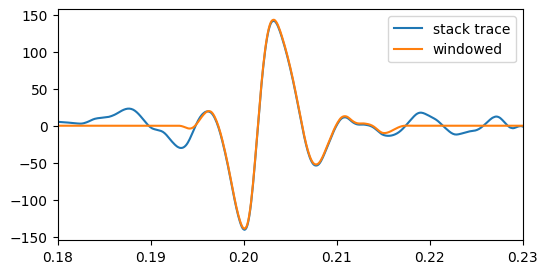

In [41]:
#Plot - Direct-wave Step 6: source time function (stack and windowed)
#QC: stack and windowed stf
plt.close('all')
plt.figure(figsize=(6, 3))
plt.plot(stf["stack"]["time"], -stf["stack"]["trace_stack"], label='stack trace')
plt.plot(stf["stack"]["time"], stf["stf_trace"]["trace"], label='windowed')
plt.legend()
plt.xlim(0.18, 0.23)
plt.show()

In [42]:
# Step 7: selected reflected data + source time function (reflection-stf inversion)
#****************************************************

ref_data = DASproc.build_ref_dict(DASrr_w, sel["trace_ids"], cc_pos, cc_neg, fit, win["noise"],
                                  params_window["time_window"], idx=sel["idx"],
                                  extra={"time_end_cc": pos_pilot_t_gate[1]})
ref_stf_data = {"stf_data": stf["stf_data"], "ref_data": ref_data}
with open("./data/ref_stf_data.pkl", "wb") as f:
    pickle.dump(ref_stf_data, f)

Reflection Plots

In [ ]:
#Plot - Pre-processing: DAS_filter panel
plt.close('all')
#plot wiggle
plt.figure(figsize=(7,4))
DAS_filter.plot_wiggle(scale=0.08,trace_step = 5,linewidth=0.5)
plt.show()

In [ ]:
#Plot - Reflected Step 2: positive-lobe cc alignment
#QC: aligned positive lobe
DASproc.plot_wiggle_zoom(pos_cc_out["DAS_shifted"], (3620, 3800), (0.22, 0.195))

In [ ]:
#Plot - Reflected Steps 2-3: traces and their max positive / negative-lobe cc
print(f'selected {sel["trace_ids"].size} of {flat_output["trace_range"].size} traces')

trace_range = flat_output["trace_range"]   # reflected trace channels on DAS_filter
drange = DAS_filter.daxis[trace_range]
#QC: selected traces and their cc
DASproc.plot_wiggle_zoom(sel["DASrr"], (3620, 3900), (0.215, 0.190), {"scale": 0.2})
plt.figure(figsize=(6, 3))
plt.plot(drange[sel["idx"]], cc_pos[sel["idx"]], label='max positive lobe cc')
if cc_neg is not None:
    plt.plot(drange[sel["idx"]], cc_neg[sel["idx"]], label='max negative lobe cc')
plt.legend()
plt.show()

In [ ]:
#Plot - Reflected Step 5 (fracture fit on the data) and Step 4 (windowed traces, saved grids)
#QC: fit on the data
sstt_out = flat_output["sstt_out"]
DASproc.plot_wiggle_zoom(DAS_filter, (3400, sstt_out['depth_end'] + 50),
                         (flat_output["SStt"][flat_output["id_end"]] + 0.02, flat_output["SStt"][flat_output["id_begin"]] - 0.02),
                         {"trace_step": 5, "figsize": (7, 4)},
                         curves=[(drange, fit["SStt_fit"], {"color": "green", "label": "fit"})])

#QC: incident and reflected rays
#DASplt.plot_reflections(drange, (xs, ys), fit["best_line_out"], fit["angles_rays"])


#QC: original vs windowed selected traces, with incidence angle (saved only: plots/reflection_w*_new.png)
files = DASproc.save_overlay_grids(DASrr_w, sel["DASrr"],
                                   angles=fit["angles_rays"]["theta_i_deg"][sel["idx"]])
print(len(files), "grids saved")

III. Transmitted waves
******************


Scattering data Processing
**************
It pairs the reflection and trasmission data. It also performs the flattening and windowing of the trasmitted traces

Processing steps (functions in `DAS_processing.py`, one parameter dictionary per function):

1. **Transmission receivers** — `transmission_receivers`: straight transmitted ray of every reflected trace (same `u_inc`) and its nearest DAS channel.
2. **Transmitted S traveltime + flattening** — `transmission_tt_flatten` (`params_tt`): polynomial fit of the S picks in a depth gate, flatten on the fit.
3. **Transmitted cc** — `transmission_cc_align` (`params_cc`): pilot = cc-aligned stack of a few traces; cc of every trace in the gate with the pilot and alignment.
4. **Pairs** — `pair_scattering_traces`: keep pairs whose transmission channel is cc-aligned; extract transmitted and reflected traces.
   - 4b. `window_scattering_traces` (`params_window`): Tukey window of both and pre-event noise of the transmitted traces.
5. **Export** — `build_scat_dict` → `scattering_data.pkl` (and `transmission_tt.pkl` from step 2).

Input: `ref_data_all` (built in memory from section I). Missing keys in a dictionary take the defaults in `DAS_processing.py`.

In [43]:
#INPUT PARAMETRES
#*********************

#Parameters of the scattering workflow (one dictionary per function)
#event, pick_file, t_ref, time_window_ref, noise_window: from the reflected-wave parameters cell

#Step 2: transmitted S traveltime fit and flattening (transmission_tt_flatten)
depth_initial=3480          # fit gate [m]
depth_final=3632
tr_poly_deg=2               # degree of the fit to the picks

#Step 3: transmitted cc (transmission_cc_align)
tr_pilot_gate=(3587, 3610)  # traces stacked into the pilot [m] (right side: (3780, 3815), dref 3802)
tr_dref=3600                # pilot reference trace [m]
tr_t_gate=(0.195, 0.21)     # cc window of pilot and traces [s]

#Step 4b: windowed traces and noise
alpha_tr=0.4                # Tukey alpha (window = time_window_ref)

#Dictionary of parameters
params_tr_tt = {"d_fit": (depth_initial, depth_final), "poly_deg": tr_poly_deg, "t_ref": t_ref}

params_tr_cc = {"pilot": {"d_gate": tr_pilot_gate, "dref": tr_dref},
                "d_gate": (depth_initial, depth_final),    # traces cc'd with the pilot [m]
                "t_gate": tr_t_gate}

params_tr_window = {"time_window": time_window_ref, "alpha": alpha_tr, "noise_window": noise_window}

In [44]:
#reflected data of all branch traces (same dictionary as Step 8a)
ref_data_all = DASproc.build_ref_dict(sel["DASrr_all"], trace_range, cc_pos, cc_neg, fit,
                                      win["noise"], params_window["time_window"],
                                      extra={"fracture_m_b": fit["best_line_out"]["line"]})

#Step 1: transmission receivers paired with the reflected traces
#************
rec = DASproc.transmission_receivers(DAS_filter, ref_data_all, event)
#rec["idx_tr"]: valid ref_data_all rows; 
# rec["idx_tr_das"], rec["idx_rr_das"]: transmission/reflection channels

#Step 2:
#********
#  transmitted S traveltime fit -> flatten
ttf = DASproc.transmission_tt_flatten(DAS_filter, pick_file, event, params_tr_tt)
with open("./data/transmission_tt.pkl", "wb") as f:
    pickle.dump(ttf["transmission_tt"], f)
#DAS object output: ttf["DAS_flat"]

#Step 3:
#********
#  pilot stack and cc alignment of the flattened transmitted traces
cco = DASproc.transmission_cc_align(ttf["DAS_flat"], params_tr_cc)
#DAS object output: cco["DAS_shifted"]; cc: cco["cc_all"]["cc_peak"]

#Step 4: 
#********
# step 4a: transmitted/reflected pairs
pairs = DASproc.pair_scattering_traces(cco["DAS_shifted"], ref_data_all, rec, cco["cc_all"])
#Step 4b: windowed traces + transmitted noise
win_sc = DASproc.window_scattering_traces(DAS_filter, pairs, params_tr_window)
scat_tr_w, scat_rr_w = win_sc["DAStr_w"], win_sc["DASrr_w"]    # windowed transmitted / reflected pairs
print(f'{pairs["idx_tr_final"].size} pairs')

#Step 5: scattering data dictionary
#***********
scattering_data = DASproc.build_scat_dict(ref_data_all, rec, pairs, win_sc)
scat_file = "./data/scattering_data.pkl"
with open(scat_file, "wb") as f:
    pickle.dump(scattering_data, f)

35 pairs


Transmitted Plots

In [ ]:
#Plot - Transmitted Step 2: S picks and fitted S traveltime
#QC: DAS_filter + S picks + fitted S traveltime
ok = ~np.isnan(ttf["S_pick"])                                    # traces with an S pick
DASproc.plot_wiggle_zoom(DAS_filter, (depth_initial - 100, depth_final + 100),
                         (np.nanmax(ttf["SStr_fit"]) + 0.05, np.nanmin(ttf["SStr_fit"]) - 0.05),
                         {"trace_step": 2},
                         curves=[(DAS_filter.daxis[ok], ttf["S_pick"][ok], {"ls": "", "marker": ".", "color": "orange", "ms": 2, "label": "S picks"}),
                                 (ttf["depth_gate"], ttf["SStr_fit"], {"color": "lime", "lw": 2, "label": "SStr_fit"})])

In [ ]:
#Plot - Transmitted Step 3: cc-aligned transmitted traces
#QC: aligned transmitted traces (Step 3)
DASproc.plot_wiggle_zoom(cco["DAS_shifted"], (depth_initial - 100, depth_final + 100),
                         (t_ref + 0.05, t_ref - 0.05), {"trace_step": 2})

In [ ]:
#Plot - Transmitted Step 4: windowed transmitted and reflected pairs
#QC: windowed transmitted and reflected traces
DASproc.plot_wiggle_zoom(scat_tr_w, (3450, 3580), (0.23, 0.18))
DASproc.plot_wiggle_zoom(scat_rr_w, (3600, 3700), (0.23, 0.18))

In [ ]:
#Plot - Transmitted Step 5: table of the exported pairs
fig_table, ax = DASplt.plot_pairs_table(scat_file, save_dir='./plots/DASplots', fname='pairs_table_new.png',
                                        figsize=(6, 1.9), font_size=10, dpi=400)

In [ ]:
#Plot - Transmitted Step 5: rays of the exported pairs
fig, ax = DASplt.plot_scattering_rays(scat_file, (xs, ys), ref_data_all['fracture_m_b'],
                                      figsize=(7, 8), xlim=(0, 130), ylim=None,
                                      label_size=12, save_path=None)
fig.savefig('./plots/DASplots/scattering_sketch_new.png', dpi=400, bbox_inches="tight")

Paper plots
*************
Figures in `./paper_plots/`. Run after sections I-III (DASdata.png needs `./data/transmission_tt.pkl`).
- DASdata.png
- reflection_geometry.png
- DASrr_all.png
- scattering_traces.png

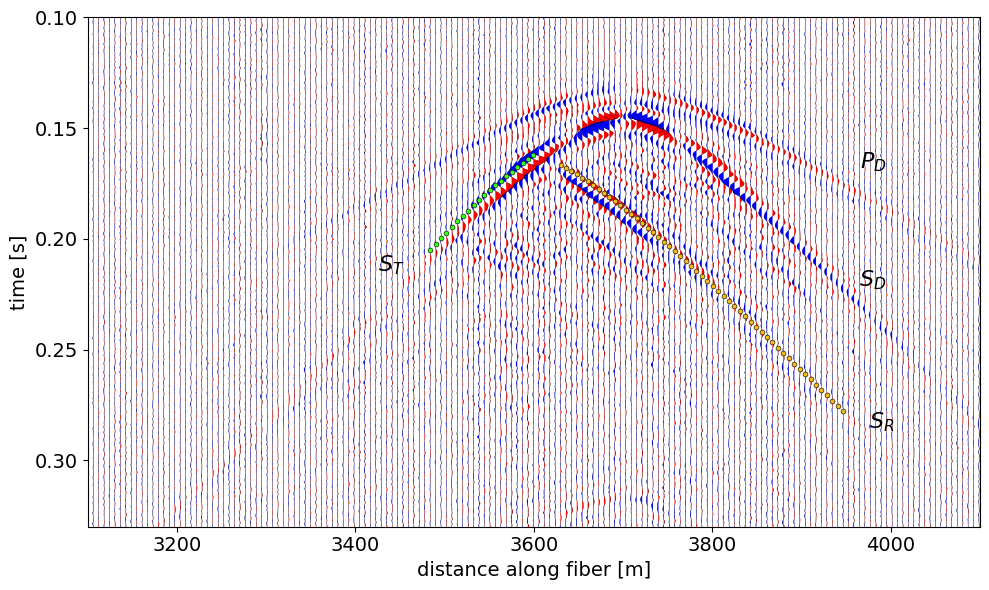

In [54]:
#Paper plot - DASdata.png: Event A panel with fitted reflection and transmission travel times (Reflected Step 5, Transmitted Step 2)
tt_file='./data/transmission_tt.pkl'
#phase labels: (depth [m], time [s]); direct-wave labels sit 12 ms above the
#straight-ray direct arrival t = ts - tfile_begin + distance / velocity
t_dir = lambda d, v: ts - tfile_begin + np.hypot(xs, d - ys) / v
labels = {r"$P_D$": (3980, t_dir(3980, vp) - 0.012),   # direct P
          r"$S_D$": (3980, t_dir(3980, vs) - 0.012),   # direct S
          r"$S_R$": (3990, 0.283),                     # reflected S (end of the reflection)
          r"$S_T$": (3440, 0.212)}                     # transmitted S (end of the transmission)

plt.close('all')
fig, ax = DASplt.plot_wiggle_reflection_tt_paper(DAS_filter,
                                                 fit["tt_fit_fracture"],
                                                 trans_tt=tt_file,
                                                 dots=True,
                                                 scale=0.08,
                                                 trace_step=6,
                                                 linewidth=0.2,
                                                 figsize=(10, 6),
                                                 xlim=(3100, 4100),
                                                 ylim=(0.10, 0.33),
                                                 label_size=14,
                                                 dot_ms=3.5,      # dot size [pt]
                                                 dot_ew=0.4,      # black edge width [pt]
                                                 labels=labels,   # phase labels
                                                 text_size=16)    # label font size [pt]
ax.set_xlabel('distance along fiber [m]', fontsize=14)   # override the function's 'depth [m]'
fig.savefig('./paper_plots/DASdata.pdf', dpi=400, bbox_inches="tight")

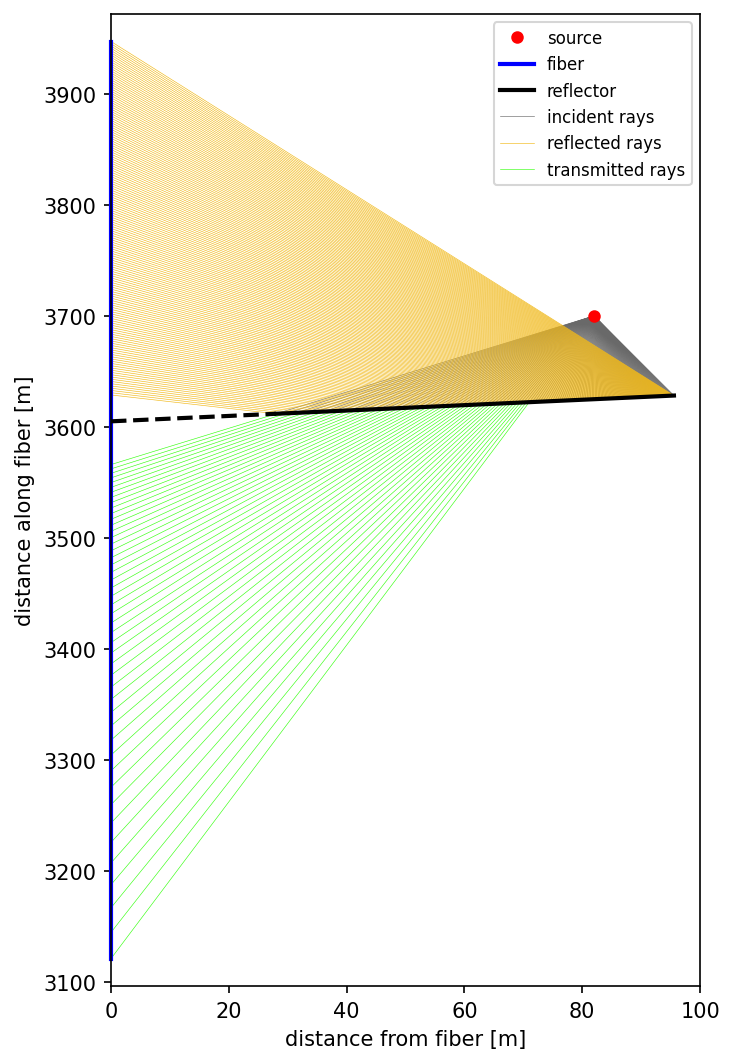

In [55]:
#Paper plot - reflection_geometry.png
#Plot - Reflected Step 5: fracture geometry and rays
#Paper figure: source, fiber, reflector, incident/reflected/transmitted rays (600 dpi)
fig, ax = DASplt.plot_reflections_paper(drange, (xs, ys), fit["best_line_out"], save_path=None)
ax.set_ylabel("distance along fiber [m]", fontsize=ax.yaxis.label.get_size())   # override the function's 'length along fiber [m]'
fig.savefig("./paper_plots/reflection_geometry.pdf", dpi=600, bbox_inches="tight")
plt.show()

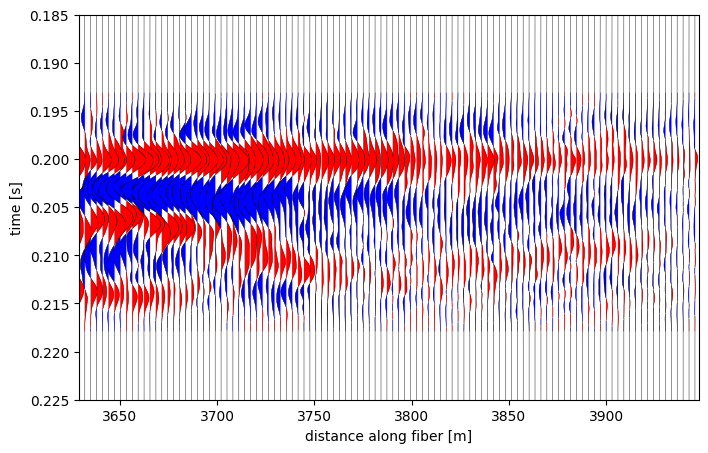

In [56]:
#Paper plot - DASrr_all.png
#Plot - Reflected Step 3: all extracted reflection traces
#All reflected branch traces (sel["DASrr_all"]), flattened and cc-aligned, high resolution (660 dpi)
das_all = DASrr_w
fig, ax = DASproc.plot_wiggle_zoom(das_all, (das_all.daxis.min(), das_all.daxis.max()), (0.225, 0.185),
                                   {"scale": 0.1, "trace_step": 3, "linewidth": 0.3, "figsize": (8, 5),
                                    "xlabel": "distance along fiber [m]"})
fig.savefig('./plots/DASplots/DASrr_all.pdf', dpi=660, bbox_inches="tight")

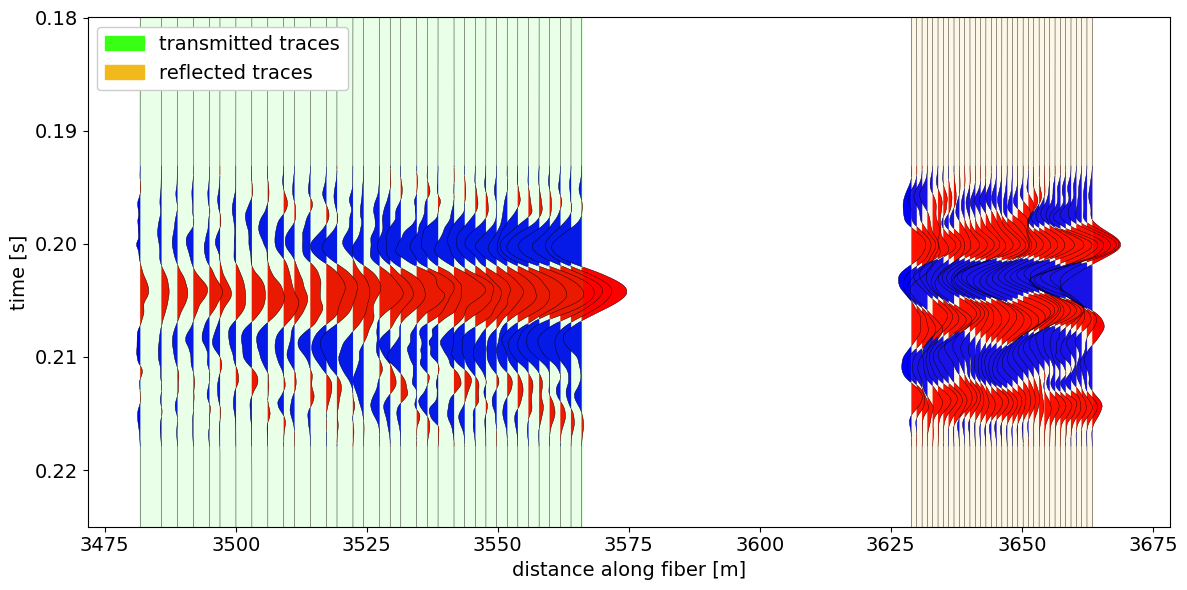

In [57]:
#Paper plot - scattering_traces.png
#Plot - Transmitted Step 4: windowed pairs in one panel
# transmitted + reflected windowed traces in one panel (x = distance along fiber, y = time)
scale = 0.1          # wiggle amplitude
step  = 1            # plot every n-th trace
plt.close('all')
fig_scat = plt.figure(figsize=(12, 6))
scat_tr_w.plot_wiggle(scale=scale, trace_step=step, linewidth=0.3)   # transmitted (shallower depths)
scat_rr_w.plot_wiggle(scale=0.08, trace_step=step, linewidth=0.3)    # reflected (deeper depths)
ax = plt.gca()
ax.set_ylim(0.225, 0.18)            # time increasing downwards
ax.axvspan(scat_tr_w.daxis.min(), scat_tr_w.daxis.max(), color='#39FF14', alpha=0.1, label='transmitted traces')
ax.axvspan(scat_rr_w.daxis.min(), scat_rr_w.daxis.max(), color='#F1B91A', alpha=0.1, label='reflected traces')
ax.set_xlabel('distance along fiber [m]', fontsize=14)
ax.set_ylabel('time [s]', fontsize=14)
ax.tick_params(labelsize=14)
leg = ax.legend(loc='upper left', fontsize=14, facecolor='white', framealpha=1)
for h in leg.legend_handles:
    h.set_alpha(1)
plt.tight_layout()
plt.show()
fig_scat.savefig('./plots/DASplots/scattering_traces_new.pdf', dpi=400, bbox_inches="tight")